# Step 3: Stage 1 (Madrid model) + Stage 2 (Amsterdam adaptation) + results
**Owners:** Silvio (stage 1), Antonio (stage 2). Run by Jian on Tue while they were away.
**Needs:** `transfer_v3.py` and the FINAL v3 feature files (`features_*_v3.parquet`, `feature_cols_v3.json`)
rebuilt after the temporal-haze step 1 rerun.

What this notebook produces (everything the brief asks for):
1. Madrid: macro F1 mean +/- std from 5-fold x 5-repeat cross-validation + confusion matrix proportions
2. The Stage 1 model trained on all Madrid pixels: `models/stage1_madrid_model.joblib`
3. Amsterdam: macro F1 mean +/- std for n = 5, 25, 50, 100, 200 labelled pixels per class (10 seeds each)
   for the official baseline (prototype), stack and our final method (blend3)
4. The results table and the plot of F1 (with error bars) vs log2(n)
5. One saved Amsterdam model per n: `models/amsterdam_blend3_n005_seed42.joblib` etc.

**Final method = blend3**, frozen from Tuesday's tests (PROJECT_LOG section 7c): average of
(a) the Madrid forest retrained with the Amsterdam support pixels weighted up,
(b) "stack": logistic regression on the Madrid model's probabilities + features,
(c) the official prototype method.

In [1]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix
import transfer_v3 as tv3

SEED = 42
N_FOLDS, N_REPEATS = 5, 5                   # Madrid CV: 25 model fits
SHOTS = [5, 25, 50, 100, 200]
N_TRIALS = 10                               # Amsterdam: 10 different random support sets per n
METHODS = ["prototype", "stack", "blend3"]  # official baseline, middle method, our final method
FINAL_METHOD = "blend3"
OFFICIAL = {5: 0.5437, 25: 0.5986, 50: 0.6079, 100: 0.6129, 200: 0.6150}   # official notebook 4
OUT = Path("models"); OUT.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)
print("scaling mode:", tv3.SCALING, "| RF:", tv3.RF_PARAMS)

scaling mode: own | RF: {'n_estimators': 300, 'class_weight': 'balanced', 'min_samples_leaf': 2, 'random_state': 42, 'n_jobs': -1}


## 1. Load the frozen v3 features

In [2]:
data = tv3.load_data(".")
print("Madrid", data["Xm"].shape, np.bincount(data["ym"])[1:])
print("Amsterdam", data["Xa"].shape, np.bincount(data["ya"])[1:])
assert data["Xm"].shape == (76263, 132) and data["Xa"].shape == (25992, 132)
assert not np.isnan(data["Xm"]).any() and not np.isnan(data["Xa"]).any()

Madrid (76263, 132) [13794 27152 18672 16645]
Amsterdam (25992, 132) [7568 8802 6745 2877]


## 2. Stage 1: Madrid cross-validation (5 folds x 5 repeats)
Each repeat shuffles Madrid into 5 parts; train on 4, test on 1. 25 scores -> mean and std.
The confusion matrix adds up every held-out prediction, then each row is divided by its total,
so each row shows where the true class went (row sums = 1).

fit  1/25: macro F1 0.6484
fit  2/25: macro F1 0.6611
fit  3/25: macro F1 0.6598
fit  4/25: macro F1 0.6534
fit  5/25: macro F1 0.6603
fit  6/25: macro F1 0.6562
fit  7/25: macro F1 0.6543
fit  8/25: macro F1 0.6533
fit  9/25: macro F1 0.6574
fit 10/25: macro F1 0.6599
fit 11/25: macro F1 0.6525
fit 12/25: macro F1 0.6595
fit 13/25: macro F1 0.6536
fit 14/25: macro F1 0.6562
fit 15/25: macro F1 0.6571
fit 16/25: macro F1 0.6614
fit 17/25: macro F1 0.6545
fit 18/25: macro F1 0.6580
fit 19/25: macro F1 0.6581
fit 20/25: macro F1 0.6530
fit 21/25: macro F1 0.6563
fit 22/25: macro F1 0.6549
fit 23/25: macro F1 0.6512
fit 24/25: macro F1 0.6559
fit 25/25: macro F1 0.6597

MADRID macro F1 = 0.6562 +/- 0.0033   (858s)
        pred 1  pred 2  pred 3  pred 4
true 1   0.549   0.366   0.048   0.037
true 2   0.140   0.711   0.095   0.054
true 3   0.038   0.220   0.637   0.105
true 4   0.022   0.119   0.157   0.702


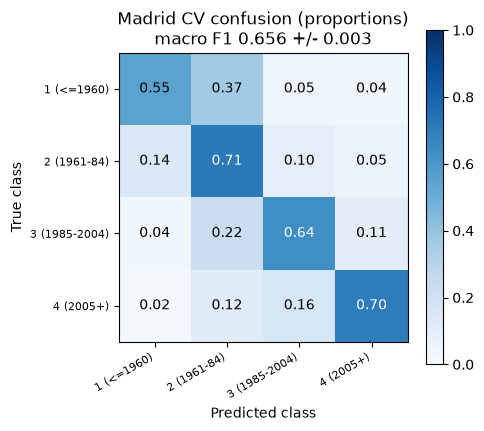

In [3]:
t = time.time()
rskf = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED)
cv_f1, cm_sum = [], np.zeros((4, 4))
for i, (tr, va) in enumerate(rskf.split(data["Xm"], data["ym"]), 1):
    rf = RandomForestClassifier(**tv3.RF_PARAMS).fit(data["Xm"][tr], data["ym"][tr])
    pred = rf.predict(data["Xm"][va])
    cv_f1.append(f1_score(data["ym"][va], pred, average="macro"))
    cm_sum += confusion_matrix(data["ym"][va], pred, labels=[1, 2, 3, 4])
    print(f"fit {i:2d}/{N_FOLDS*N_REPEATS}: macro F1 {cv_f1[-1]:.4f}")
madrid_mean, madrid_std = np.mean(cv_f1), np.std(cv_f1)
cm_prop = cm_sum / cm_sum.sum(axis=1, keepdims=True)
print(f"\nMADRID macro F1 = {madrid_mean:.4f} +/- {madrid_std:.4f}   ({time.time()-t:.0f}s)")
cm_df = pd.DataFrame(cm_prop.round(3), index=[f"true {c}" for c in range(1, 5)],
                     columns=[f"pred {c}" for c in range(1, 5)])
print(cm_df)
cm_df.to_csv(RES / "madrid_confusion_proportions.csv")
pd.DataFrame({"fit": range(1, len(cv_f1) + 1), "macro_f1": cv_f1}).to_csv(RES / "madrid_cv_scores.csv", index=False)

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm_prop, cmap="Blues", vmin=0, vmax=1)
labels = ["1 (<=1960)", "2 (1961-84)", "3 (1985-2004)", "4 (2005+)"]
ax.set_xticks(range(4)); ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(4)); ax.set_yticklabels(labels, fontsize=8)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm_prop[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_prop[i, j] > 0.6 else "black")
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title(f"Madrid CV confusion (proportions)\nmacro F1 {madrid_mean:.3f} +/- {madrid_std:.3f}")
plt.colorbar(im); plt.tight_layout(); plt.savefig(RES / "madrid_confusion.png", dpi=150); plt.show()

## 3. Stage 1 final model: train on ALL Madrid pixels and save it (deliverable 1)

In [4]:
stage1 = tv3.train_stage1(data)
joblib.dump({"rf": stage1["rf"], "scaler_amsterdam": stage1["scaler_a"],
             "feature_cols": data["cols"], "rf_params": tv3.RF_PARAMS, "scaling": tv3.SCALING},
            OUT / "stage1_madrid_model.joblib")
print("saved", OUT / "stage1_madrid_model.joblib")
zero = f1_score(data["ya"], tv3.CLASSES[stage1["LPa"].argmax(1)], average="macro")
print(f"zero-shot Amsterdam (no Amsterdam labels): {zero:.4f}   (official: 0.3427)")

saved models/stage1_madrid_model.joblib
zero-shot Amsterdam (no Amsterdam labels): 0.4525   (official: 0.3427)


## 4. Stage 2: Amsterdam adaptation for every n, 10 seeds each, every method
Same 10 support sets (seeds 42 to 51) for every method, so the comparison is fair.
blend3 retrains a forest 50 times, so this cell takes several minutes.

In [5]:
t = time.time()
all_res = []
for m in METHODS:
    r = tv3.evaluate(data, stage1, m, shots=SHOTS, trials=N_TRIALS)
    all_res.append(r)
    print(f"{m:10s}", " ".join(f"n{int(n)}:{f:.3f}+/-{s:.3f}" for n, f, s in
                               zip(r.n_per_class, r.f1_mean, r.f1_std)),
          f"| avg {r.f1_mean.mean():.4f}  ({time.time()-t:.0f}s)")
res = pd.concat(all_res, ignore_index=True)
res.to_csv(RES / "amsterdam_all_methods.csv", index=False)

prototype  n5:0.532+/-0.053 n25:0.581+/-0.016 n50:0.603+/-0.022 n100:0.608+/-0.007 n200:0.615+/-0.005 | avg 0.5878  (8s)
stack      n5:0.552+/-0.047 n25:0.616+/-0.018 n50:0.639+/-0.016 n100:0.651+/-0.004 n200:0.684+/-0.005 | avg 0.6283  (25s)
blend3     n5:0.580+/-0.038 n25:0.641+/-0.012 n50:0.666+/-0.012 n100:0.683+/-0.005 n200:0.703+/-0.004 | avg 0.6546  (1470s)


## 5. Results table for the slides (final method) + F1 vs log2(n) plot

               setting  macro_F1_mean  macro_F1_std  official_reference
       Madrid (5x5 CV)         0.6562        0.0033              0.6179
   Amsterdam n=5/class         0.5801        0.0376              0.5437
  Amsterdam n=25/class         0.6410        0.0125              0.5986
  Amsterdam n=50/class         0.6656        0.0117              0.6079
 Amsterdam n=100/class         0.6831        0.0051              0.6129
 Amsterdam n=200/class         0.7031        0.0036              0.6150
Amsterdam average of 5         0.6546           NaN              0.5956


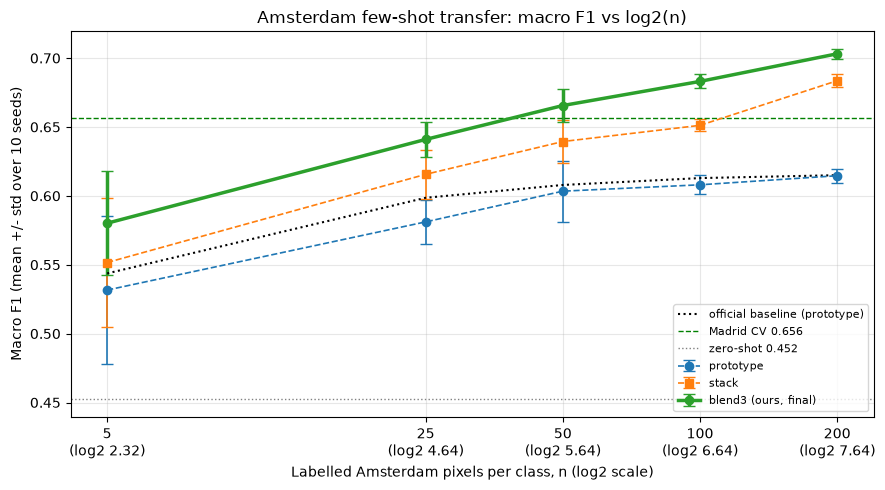

In [6]:
fin = res[res.method == FINAL_METHOD].set_index("n_per_class")
table = pd.DataFrame({
    "setting": ["Madrid (5x5 CV)"] + [f"Amsterdam n={n}/class" for n in SHOTS] + ["Amsterdam average of 5"],
    "macro_F1_mean": [madrid_mean] + [fin.loc[n, "f1_mean"] for n in SHOTS] + [fin.f1_mean.mean()],
    "macro_F1_std": [madrid_std] + [fin.loc[n, "f1_std"] for n in SHOTS] + [np.nan],
    "official_reference": [0.6179] + [OFFICIAL[n] for n in SHOTS] + [np.mean(list(OFFICIAL.values()))],
}).round(4)
table.to_csv(RES / "results_table.csv", index=False)
print(table.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
x = np.log2(SHOTS)
for m, style in zip(METHODS, ["o--", "s--", "o-"]):
    r = res[res.method == m]
    ax.errorbar(x, r.f1_mean, yerr=r.f1_std, fmt=style, capsize=4,
                linewidth=2.5 if m == FINAL_METHOD else 1.2,
                label=("blend3 (ours, final)" if m == FINAL_METHOD else m))
ax.plot(x, [OFFICIAL[n] for n in SHOTS], "k:", label="official baseline (prototype)")
ax.axhline(madrid_mean, color="green", ls="--", lw=1, label=f"Madrid CV {madrid_mean:.3f}")
ax.axhline(zero, color="grey", ls=":", lw=1, label=f"zero-shot {zero:.3f}")
ax.set_xticks(x); ax.set_xticklabels([f"{n}\n(log2 {v:.2f})" for n, v in zip(SHOTS, x)])
ax.set_xlabel("Labelled Amsterdam pixels per class, n (log2 scale)")
ax.set_ylabel("Macro F1 (mean +/- std over 10 seeds)")
ax.set_title("Amsterdam few-shot transfer: macro F1 vs log2(n)")
ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(RES / "f1_vs_log2n.png", dpi=150); plt.show()

## 6. Save one Amsterdam model per n (final method, seed 42)
Each file holds everything needed to re-apply the model: the retrained forest, the stack logistic
regression and the class prototypes. `tv3.predict_blend3(model, stage1, X_new)` applies it.

In [7]:
for n in SHOTS:
    f1, model = tv3.adapt_to_amsterdam(data, stage1, n, SEED, FINAL_METHOD)
    path = OUT / f"amsterdam_{FINAL_METHOD}_n{n:03d}_seed{SEED}.joblib"
    joblib.dump(model, path)
    # check the saved model reproduces the same predictions on its own query pixels
    qry = np.setdiff1d(np.arange(len(data["ya"])), model["support_index"])
    again = f1_score(data["ya"][qry], tv3.predict_blend3(joblib.load(path), stage1, data["Xa"][qry]),
                     average="macro")
    print(f"saved {path.name}: F1 {f1:.4f} | reloaded F1 {again:.4f}")
    assert abs(f1 - again) < 1e-9, "saved model does not reproduce its score"
print("all models saved and verified")

saved amsterdam_blend3_n005_seed42.joblib: F1 0.5204 | reloaded F1 0.5204
saved amsterdam_blend3_n025_seed42.joblib: F1 0.6286 | reloaded F1 0.6286
saved amsterdam_blend3_n050_seed42.joblib: F1 0.6615 | reloaded F1 0.6615
saved amsterdam_blend3_n100_seed42.joblib: F1 0.6826 | reloaded F1 0.6826
saved amsterdam_blend3_n200_seed42.joblib: F1 0.6987 | reloaded F1 0.6987
all models saved and verified


In [9]:
# Section 7: blend3 + spatial smoothing (same seeds as section 4, so the comparison is fair)
from sklearn.linear_model import LogisticRegression
ids_a = pd.read_parquet("features_amsterdam_v3.parquet", columns=["px_key", "py_key"]).to_numpy()  # same row order as data
rows = []
for n in SHOTS:
    plain, smooth = [], []
    for t in range(N_TRIALS):
        sup, qry = tv3.sample_support(data["ya"], n, SEED + t)      # same support sets as before
        ys = data["ya"][sup]
        Pf, _ = tv3.finetune_proba(data, sup, qry)                  # (a) fine-tuned forest
        lr = LogisticRegression(C=tv3._c_for(n), max_iter=5000).fit(stage1["Zst"][sup], ys)  # (b) stack
        P = (Pf + lr.predict_proba(stage1["Zst"][qry]) + tv3.proto_proba(stage1["Za"], ys, sup, qry)) / 3
        S = tv3.smooth_proba(P, ids_a[qry], 0.5)                    # neighbours = other query pixels only
        plain.append(f1_score(data["ya"][qry], tv3.CLASSES[P.argmax(1)], average="macro"))
        smooth.append(f1_score(data["ya"][qry], tv3.CLASSES[S.argmax(1)], average="macro"))
    rows.append({"n_per_class": n, "blend3": np.mean(plain), "blend3_std": np.std(plain),
                 "blend3_smoothed": np.mean(smooth), "smoothed_std": np.std(smooth),
                 "wins_out_of_10": int((np.array(smooth) > np.array(plain)).sum())})
smooth_table = pd.DataFrame(rows).round(4)
smooth_table.to_csv(RES / "amsterdam_smoothing.csv", index=False)
print(smooth_table.to_string(index=False))
print("average blend3:", smooth_table.blend3.mean().round(4), "| average smoothed:", smooth_table.blend3_smoothed.mean().round(4))

 n_per_class  blend3  blend3_std  blend3_smoothed  smoothed_std  wins_out_of_10
           5  0.5801      0.0376           0.5934        0.0405              10
          25  0.6410      0.0125           0.6584        0.0118              10
          50  0.6656      0.0117           0.6835        0.0118              10
         100  0.6831      0.0051           0.7022        0.0060              10
         200  0.7031      0.0036           0.7194        0.0047              10
average blend3: 0.6546 | average smoothed: 0.6714


In [3]:
# ===== Stage 1 model comparison on Madrid =====
# Same 5 test splits for every model, so the scores are directly comparable.
# Decision rule (agreed before running): keep RandomForest unless a model beats it by more than 0.01.
import time
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

MODELS = {
    # our current model (should give about 0.657, confirming the test matches earlier runs)
    "RandomForest (current)": lambda: RandomForestClassifier(**tv3.RF_PARAMS),
    # like RandomForest but with more random splits
    "ExtraTrees": lambda: ExtraTreesClassifier(n_estimators=300, class_weight="balanced",
                                               min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    # boosting: each new tree fixes the previous trees' mistakes
    "HistGradientBoosting": lambda: HistGradientBoostingClassifier(max_iter=400, learning_rate=0.06,
                                               class_weight="balanced", random_state=SEED),
    # simple linear baseline (scaler is fitted inside each fold, so no leakage)
    "LogisticRegression": lambda: make_pipeline(StandardScaler(),
                                               LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000)),
    # small neural network, stops early when it stops improving
    "NeuralNet (MLP)": lambda: make_pipeline(StandardScaler(),
                                               MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True,
                                                             max_iter=200, random_state=SEED)),
    # labels a pixel by its 15 most similar Madrid pixels
    "kNN (k=15)": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15, n_jobs=-1)),
}

folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(data["Xm"], data["ym"]))
rows = []
for name, make in MODELS.items():
    t = time.time()
    scores = []
    for tr, te in folds:
        model = make().fit(data["Xm"][tr], data["ym"][tr])            # train on 4 folds
        scores.append(f1_score(data["ym"][te], model.predict(data["Xm"][te]), average="macro"))  # test on 1
    rows.append({"model": name, "macro_F1": np.mean(scores), "std": np.std(scores),
                 "seconds": round(time.time() - t)})
    print(f"{name:24s} {np.mean(scores):.4f} +/- {np.std(scores):.4f}  ({time.time()-t:.0f}s)")

comparison = pd.DataFrame(rows).sort_values("macro_F1", ascending=False).round(4)
comparison.to_csv(RES / "stage1_model_comparison.csv", index=False)
best = comparison.iloc[0]
rf_score = comparison.loc[comparison.model == "RandomForest (current)", "macro_F1"].iloc[0]
print("\n", comparison.to_string(index=False))
if best.model != "RandomForest (current)" and best.macro_F1 - rf_score > 0.01:
    print(f"\n{best.model} beats RandomForest by {best.macro_F1 - rf_score:.4f}: test it in the Amsterdam step before switching.")
else:
    print("\nKeep RandomForest: no model beats it by more than 0.01.")

RandomForest (current)   0.6566 +/- 0.0050  (226s)
ExtraTrees               0.6482 +/- 0.0054  (70s)
HistGradientBoosting     0.6611 +/- 0.0044  (2280s)
LogisticRegression       0.6040 +/- 0.0047  (397s)
NeuralNet (MLP)          0.6536 +/- 0.0051  (139s)
kNN (k=15)               0.6276 +/- 0.0039  (8s)

                  model  macro_F1    std  seconds
  HistGradientBoosting    0.6611 0.0044     2280
RandomForest (current)    0.6566 0.0050      226
       NeuralNet (MLP)    0.6536 0.0051      139
            ExtraTrees    0.6482 0.0054       70
            kNN (k=15)    0.6276 0.0039        8
    LogisticRegression    0.6040 0.0047      397

Keep RandomForest: no model beats it by more than 0.01.
